# 🚌 Trasporto pubblico a Napoli: i quartieri sono serviti allo stesso modo?

Progetto di **Francesco Autorino** – Data Analyst.

❓ **La domanda**: i 30 quartieri di Napoli sono serviti in modo simile da autobus, metro e funicolari?

Le 5 domande più piccole:

1️⃣ 🚏 Dove ci sono più fermate e più linee?

2️⃣ 🔁 Quante corse passano, e in quali ore?

3️⃣ 🚶 Quanta strada si fa per arrivare alla fermata più vicina?

4️⃣ 🚇 Chi ha vicino una metro o una funicolare?

5️⃣ 🏆 Quali quartieri sono serviti meglio e quali peggio?

📊 Dati: GTFS di ANM (Open Data Comune di Napoli) con linee, fermate e orari programmati,
quartieri e abitanti del censimento ISTAT 2021 (4.219 sezioni abitate).

📅 Giorno tipo: **mercoledì 18 ottobre 2023**. Distanze in linea d'aria.

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

DATI = Path("../02Dati/2Puliti")
GRAFICI = Path("Grafici"); GRAFICI.mkdir(exist_ok=True)
q = pd.read_csv(DATI / "quartieri.csv")
mun = pd.read_csv(DATI / "municipalita.csv")
fer = pd.read_csv(DATI / "fermate.csv", dtype={"stop_id": str})
sez = pd.read_csv(DATI / "sezioni.csv")
linee = pd.read_csv(DATI / "linee.csv")
ore = pd.read_csv(DATI / "corse_per_ora.csv")
confini = gpd.read_file(DATI / "quartieri_confini.geojson").merge(q[["id_quartiere", "punteggio_servizio", "giudizio"]], on="id_quartiere")

# colori del progetto: blu golfo, giallo tufo, rosso pomodoro, verde
GOLFO, TUFO, POMODORO, VERDE, GRIGIO = "#123B5C", "#F2B134", "#D1495B", "#2A9D8F", "#8A94A6"
MODO = {"Bus": "#2E86AB", "Metro": POMODORO, "Funicolare": TUFO}
GIUDIZIO = {"Servito bene": VERDE, "Nella media": TUFO, "Servito poco": POMODORO}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10})

def salva(nome):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", bbox_inches="tight"); plt.show()

nap = fer[(fer.in_citta == "Sì") & (fer.corse_giorno > 0)]
pesata = lambda c: np.average(q[c], weights=q["abitanti"])
print(f"Abitanti: {int(q.abitanti.sum()):,} · fermate usate: {len(nap):,} · linee: {len(linee)}".replace(",", "."))
linee.modo.value_counts()

Abitanti: 921.142 · fermate usate: 1.839 · linee: 107


modo
Bus           101
Funicolare      4
Metro           2
Name: count, dtype: int64

## 1️⃣ 🚏 Dove ci sono più fermate e più linee?

📌 Contiamo solo le fermate **dentro il Comune** e con **almeno una corsa** nel giorno tipo.

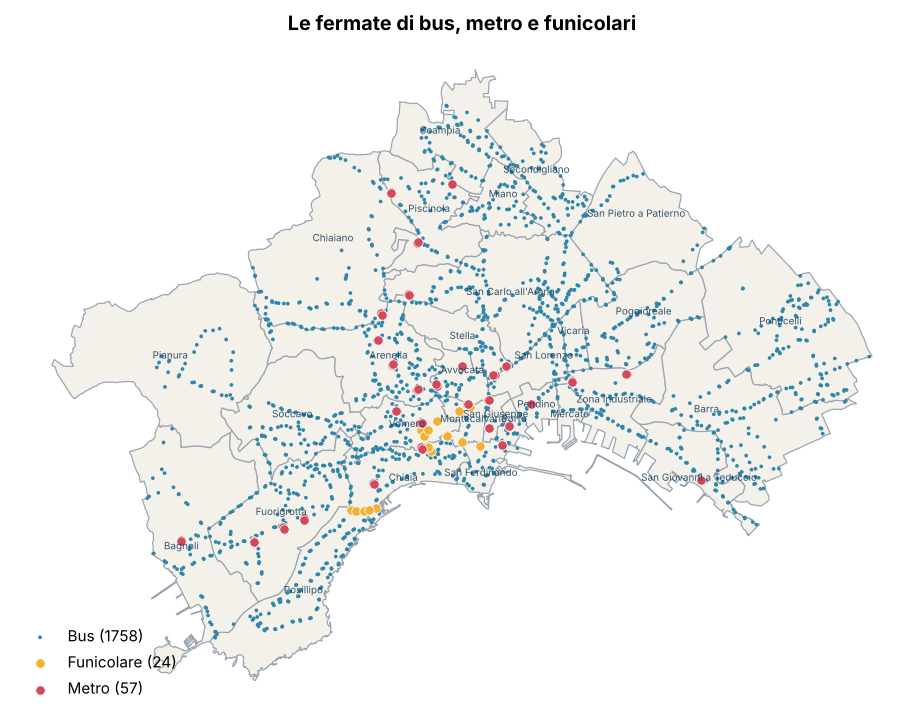

In [2]:
fig, ax = plt.subplots(figsize=(8.5, 8.5))
confini.plot(ax=ax, color="#F4F1EA", edgecolor="#9AA5B1", linewidth=0.8)
for m in ["Bus", "Funicolare", "Metro"]:
    d = nap[nap.modo == m]
    ax.scatter(d.stop_lon, d.stop_lat, s=6 if m == "Bus" else 38, color=MODO[m], label=f"{m} ({len(d)})", zorder=3,
               edgecolor="white" if m != "Bus" else "none", linewidth=0.5)
for _, r in q.iterrows():
    ax.text(r.longitudine, r.latitudine, r.quartiere, fontsize=6.5, ha="center", color=GOLFO, alpha=0.85)
ax.set_axis_off(); ax.legend(loc="lower left", frameon=False); ax.set_title("Le fermate di bus, metro e funicolari")
salva("01_mappa_fermate")

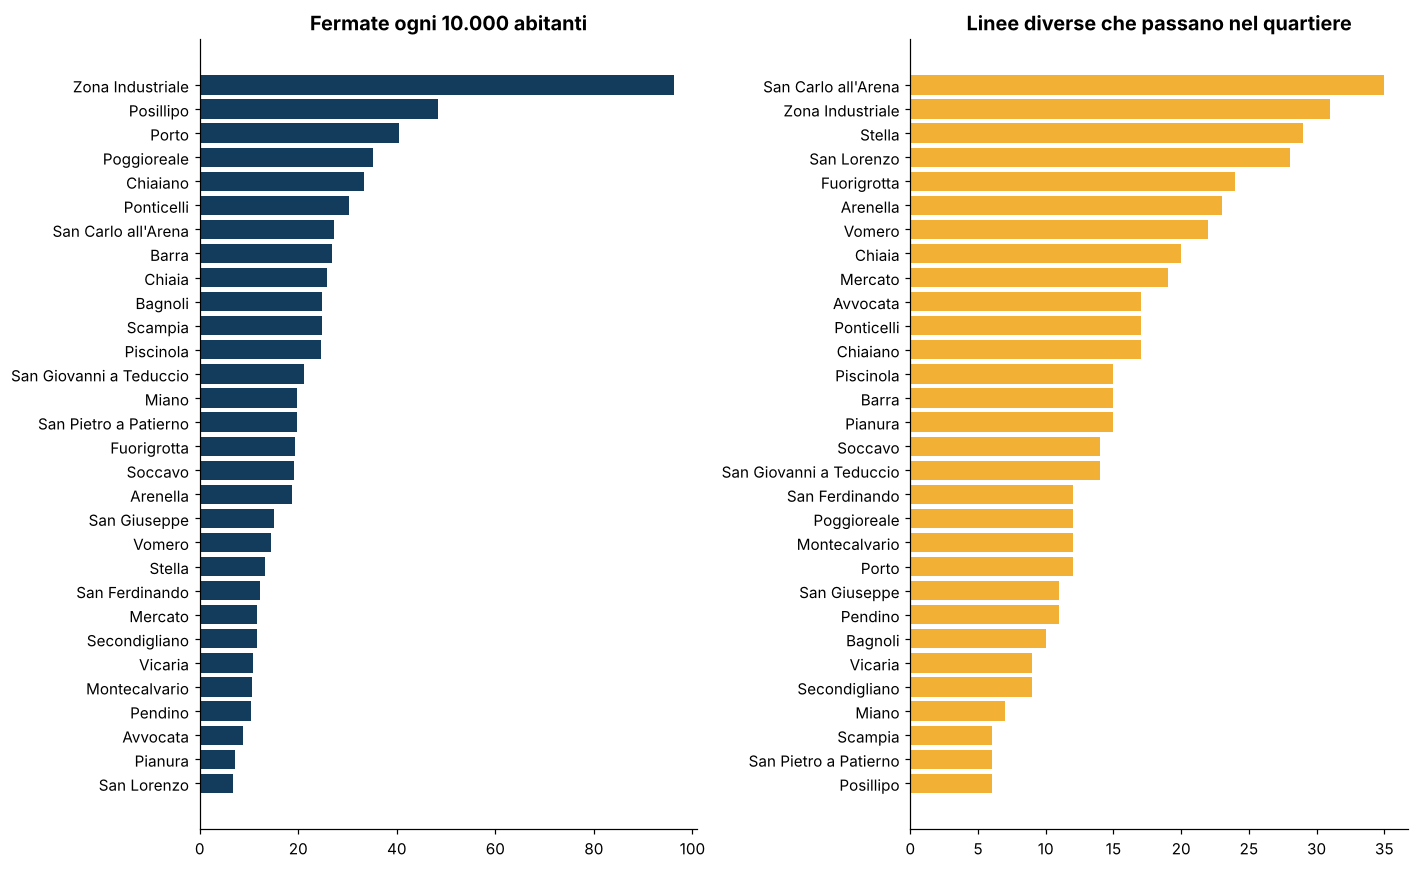

,quartiere,abitanti,n_fermate,fermate_10mila_ab,fermate_km2,n_linee
6,San Carlo all'Arena,63860.0,174,27.2,22.9,35
18,Fuorigrotta,67608.0,131,19.4,20.1,24
13,Arenella,67539.0,126,18.7,24.3,23
27,Ponticelli,39335.0,119,30.3,12.6,17
14,Posillipo,22081.0,107,48.5,21.6,6
1,Chiaia,40730.0,105,25.8,37.3,20
28,Barra,33829.0,91,26.9,11.7,15
21,Chiaiano,23960.0,80,33.4,8.3,17
19,Soccavo,39499.0,76,19.2,14.9,14
15,Poggioreale,20997.0,74,35.2,16.1,12


In [3]:
o = q.sort_values("fermate_10mila_ab")
fig, ax = plt.subplots(1, 2, figsize=(13, 8), sharey=False)
ax[0].barh(o.quartiere, o.fermate_10mila_ab, color=GOLFO)
ax[0].set_title("Fermate ogni 10.000 abitanti")
o2 = q.sort_values("n_linee")
ax[1].barh(o2.quartiere, o2.n_linee, color=TUFO)
ax[1].set_title("Linee diverse che passano nel quartiere")
salva("02_fermate_linee")
q.sort_values("n_fermate", ascending=False)[["quartiere", "abitanti", "n_fermate", "fermate_10mila_ab", "fermate_km2", "n_linee"]].head(10).round(1)

💡 **Cosa vediamo**

📌 I quartieri grandi e popolosi hanno più fermate: **San Carlo all'Arena** (174), **Fuorigrotta** (131), **Arenella** (126).

📌 Rispetto agli abitanti, le fermate sono di più nei quartieri poco abitati (Zona Industriale, Posillipo).

📌 Le fermate **per abitante** sono poche nei quartieri molto densi del centro (San Lorenzo, Avvocata, Pendino): lì le persone sono tante, ma le distanze sono brevi.

## 2️⃣ 🔁 Quante corse passano, e in quali ore?

📌 **Passaggio** = un mezzo che si ferma a una fermata. Una corsa con 30 fermate fa 30 passaggi.

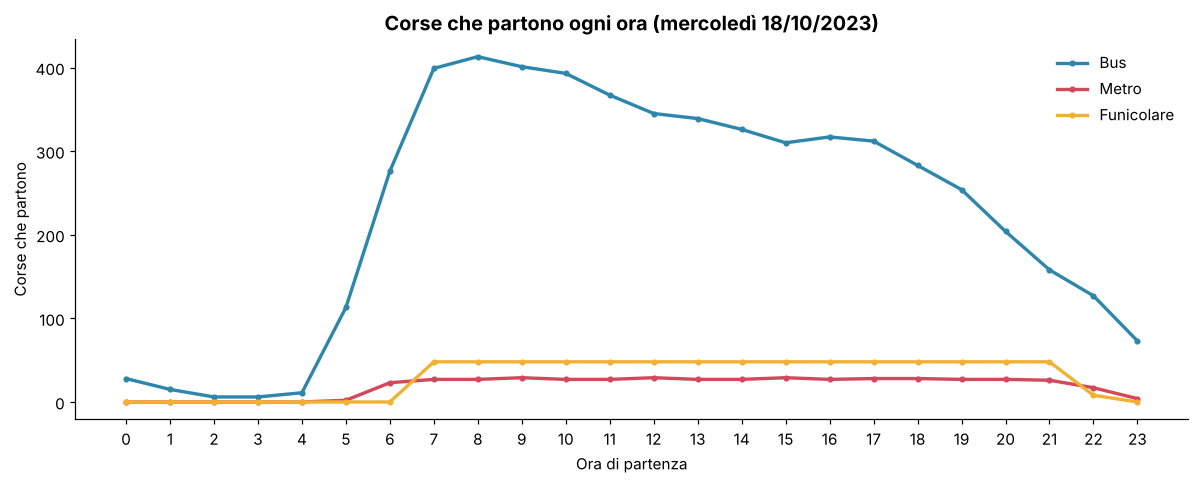

Corse del giorno: 6662 · di notte (0-5): 66


,linea,modo,azienda,corse_giorno,n_fermate,prima_corsa,ultima_corsa
101,F4,Funicolare,ANM,182,8,07:00,22:08
102,F1,Funicolare,ANM,182,6,07:00,22:06
103,F3,Funicolare,ANM,182,6,07:00,22:07
104,F2,Funicolare,ANM,182,4,07:00,22:07
105,L2,Metro,Trenitalia,244,22,05:43,00:04
106,L1,Metro,ANM,214,36,06:00,23:35


In [4]:
p = ore.pivot(index="ora", columns="modo", values="corse").fillna(0)
fig, ax = plt.subplots(figsize=(11, 4.5))
for m in ["Bus", "Metro", "Funicolare"]:
    ax.plot(p.index, p[m], marker="o", ms=3, color=MODO[m], lw=2.2, label=m)
ax.set_xticks(range(0, 24)); ax.set_xlabel("Ora di partenza"); ax.set_ylabel("Corse che partono")
ax.set_title("Corse che partono ogni ora (mercoledì 18/10/2023)"); ax.legend(frameon=False)
salva("03_corse_per_ora")
print("Corse del giorno:", int(ore.corse.sum()), "· di notte (0-5):", int(ore[ore.ora < 5].corse.sum()))
linee[linee.modo != "Bus"][["linea", "modo", "azienda", "corse_giorno", "n_fermate", "prima_corsa", "ultima_corsa"]]

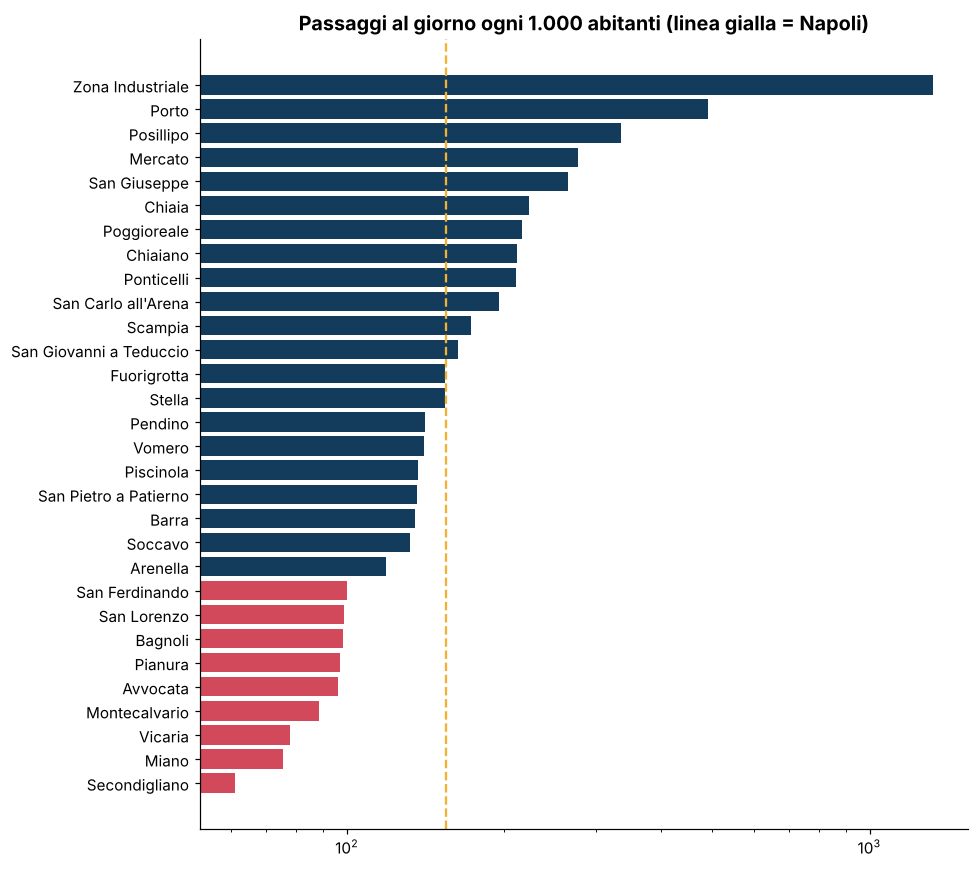

In [5]:
o = q.sort_values("passaggi_1000_ab")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(o.quartiere, o.passaggi_1000_ab, color=[POMODORO if v < 100 else GOLFO for v in o.passaggi_1000_ab])
ax.axvline(q.passaggi_giorno.sum() / q.abitanti.sum() * 1000, color=TUFO, ls="--", lw=1.5)
ax.set_title("Passaggi al giorno ogni 1.000 abitanti (linea gialla = Napoli)"); ax.set_xscale("log")
salva("04_passaggi_abitanti")

💡 **Cosa vediamo**

📌 Nel giorno tipo partono **6.662 corse**. Il picco è tra le **7 e le 10**.

📌 Di notte (da mezzanotte alle 5) restano solo poche decine di bus.

📌 Le **funicolari** vanno dalle 7 alle 22; la **Linea 1** dalle 6 alle 23:35.

📌 **Secondigliano**, **Miano** e **Vicaria** hanno meno di 80 passaggi ogni 1.000 abitanti: circa la metà della media di Napoli (155).

📌 La Zona Industriale è "fuori scala" perché ci sono i capolinea vicino a piazza Garibaldi e pochi abitanti.

## 3️⃣ 🚶 Quanta strada per arrivare alla fermata?

📌 Per ogni **sezione di censimento** (un isolato o poco più) misuriamo la distanza dalla fermata più vicina.

📌 Poi facciamo la media **pesata sugli abitanti**: conta di più dove abitano più persone.

📌 **300 metri** = circa 4 minuti a piedi.

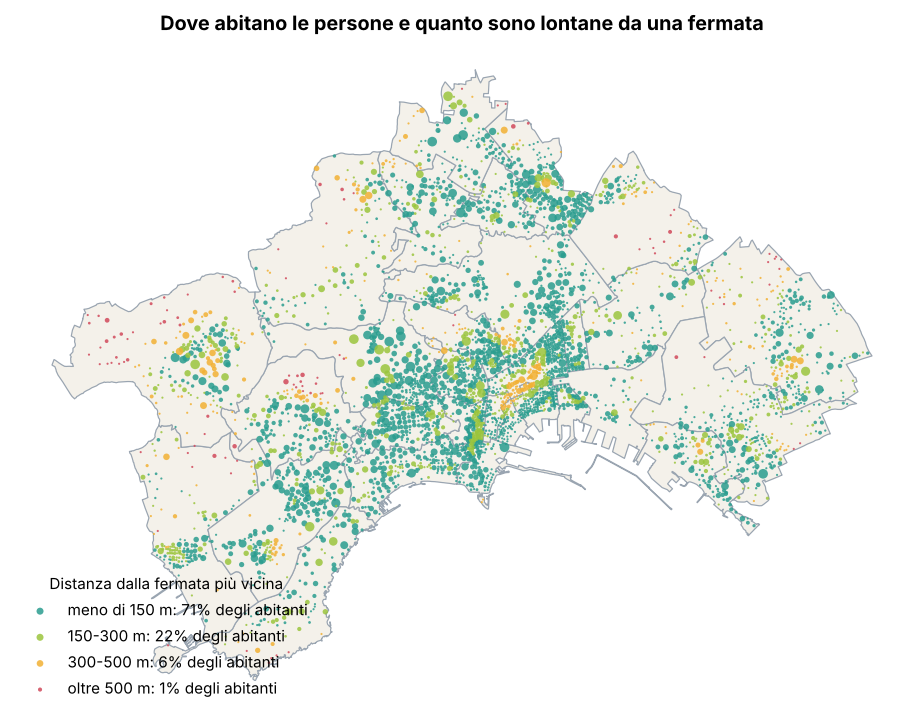

,abitanti,pct
fascia_distanza,,
meno di 150 m,653521,70.9
150-300 m,201303,21.9
300-500 m,57140,6.2
oltre 500 m,9178,1.0


In [6]:
fasce = {"meno di 150 m": VERDE, "150-300 m": "#9BC53D", "300-500 m": TUFO, "oltre 500 m": POMODORO}
fig, ax = plt.subplots(figsize=(8.5, 8.5))
confini.plot(ax=ax, color="#F4F1EA", edgecolor="#9AA5B1", linewidth=0.8)
for f, c in fasce.items():
    d = sez[sez.fascia_distanza == f]
    ax.scatter(d.longitudine, d.latitudine, s=np.clip(d.abitanti / 40, 2, 40), color=c, label=f"{f}: {d.abitanti.sum() / sez.abitanti.sum() * 100:.0f}% degli abitanti", alpha=0.85, edgecolor="none")
ax.set_axis_off(); ax.legend(loc="lower left", frameon=False, title="Distanza dalla fermata più vicina")
ax.set_title("Dove abitano le persone e quanto sono lontane da una fermata")
salva("05_mappa_distanza")
sez.groupby("fascia_distanza").abitanti.sum().reindex(list(fasce)).to_frame().assign(pct=lambda d: (d.abitanti / d.abitanti.sum() * 100).round(1))

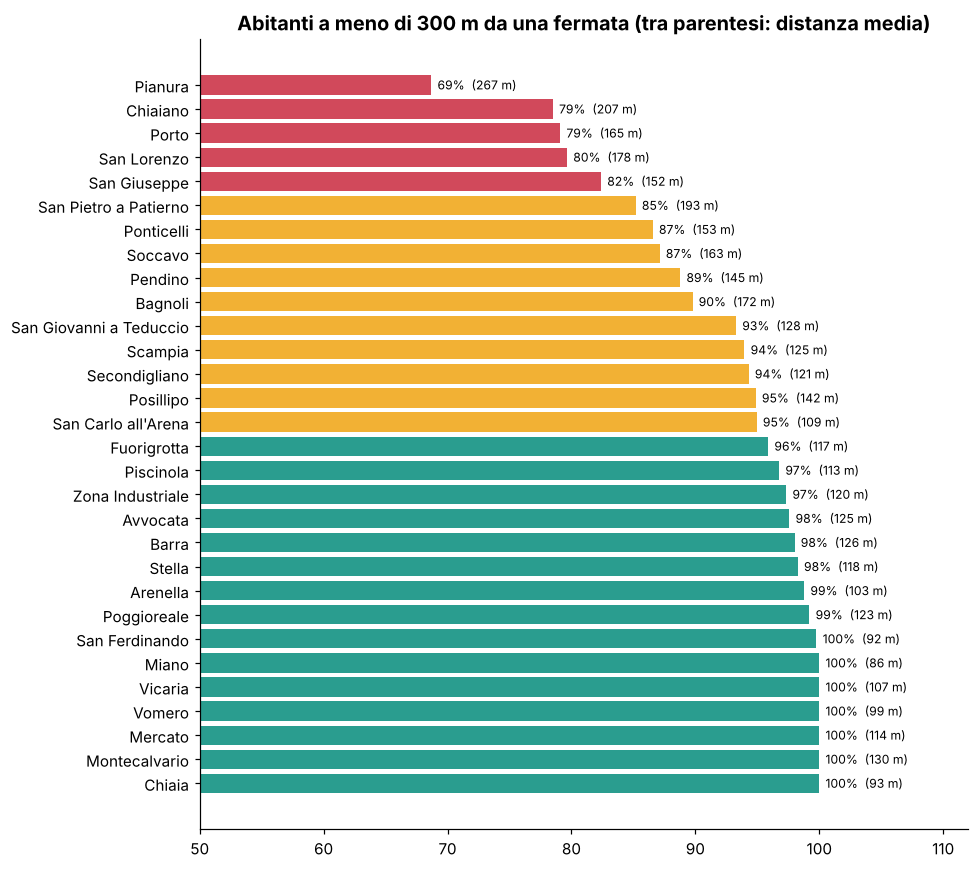

Napoli: 92.8% entro 300 m · distanza media 135 m


,quartiere,dist_media_fermata_m,pct_entro_300m,over65,pct_over65_entro_300m
20,Pianura,267.4,68.7,9506.0,69.2
21,Chiaiano,207.3,78.5,4806.0,79.6
26,San Pietro a Patierno,192.7,85.2,2576.0,86.2
8,San Lorenzo,178.1,79.6,8698.0,81.2
17,Bagnoli,171.7,89.8,5113.0,90.8
11,Porto,165.1,79.1,988.0,76.7


In [7]:
o = q.sort_values("pct_entro_300m", ascending=False)
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(o.quartiere, o.pct_entro_300m, color=[POMODORO if v < 85 else (TUFO if v < 95 else VERDE) for v in o.pct_entro_300m])
for y, (v, d) in enumerate(zip(o.pct_entro_300m, o.dist_media_fermata_m)):
    ax.text(v + 0.5, y, f"{v:.0f}%  ({d:.0f} m)", va="center", fontsize=8)
ax.set_xlim(50, 112); ax.set_title("Abitanti a meno di 300 m da una fermata (tra parentesi: distanza media)")
salva("06_entro_300m")
print(f"Napoli: {pesata('pct_entro_300m'):.1f}% entro 300 m · distanza media {pesata('dist_media_fermata_m'):.0f} m")
q.sort_values("dist_media_fermata_m", ascending=False)[["quartiere", "dist_media_fermata_m", "pct_entro_300m", "over65", "pct_over65_entro_300m"]].head(6).round(1)

💡 **Cosa vediamo**

📌 A Napoli le fermate sono **vicine quasi a tutti**: 9 abitanti su 10 ne hanno una a meno di 300 metri.

📌 La distanza media è di circa **135 metri**.

📌 I quartieri dove si cammina di più sono **Pianura** (267 m, solo 69% entro 300 m), **Chiaiano** e **San Pietro a Patierno**: quartieri grandi, in collina o in periferia.

📌 A Pianura quasi **3.000 anziani** abitano a più di 300 metri da una fermata.

## 4️⃣ 🚇 Chi ha vicino una metro o una funicolare?

📌 Metro (Linea 1 di ANM e Linea 2 di Trenitalia) e funicolari sono più veloci e non hanno traffico.

📌 **800 metri** = circa 10 minuti a piedi.

⚠️ Nel GTFS di ANM **non ci sono** Cumana, Circumflegrea e Circumvesuviana (sono di EAV): in alcuni quartieri (Pianura, Soccavo, Ponticelli, Barra) i treni ci sono, ma non sono contati.

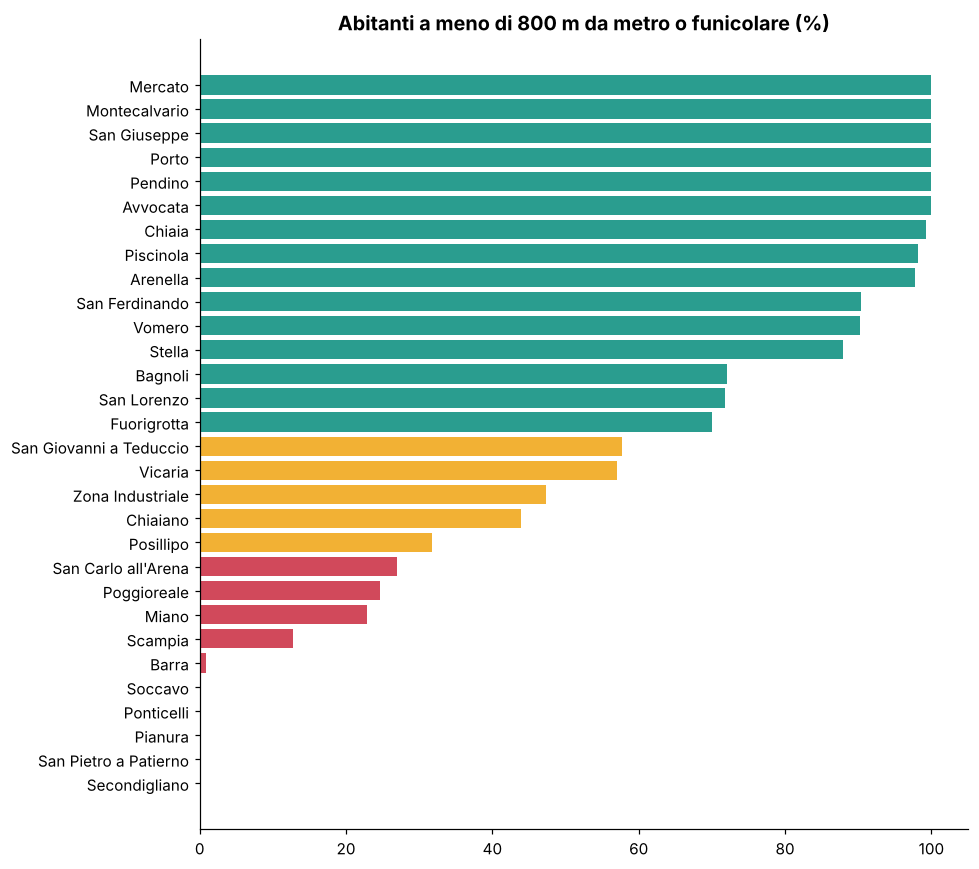

Quartieri con nessun abitante entro 800 m: Soccavo. Pianura. Secondigliano. San Pietro a Patierno. Ponticelli → 195.338 abitanti
Napoli: 53.2% degli abitanti entro 800 m da metro o funicolare


In [8]:
o = q.sort_values("pct_stazione_800m")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(o.quartiere, o.pct_stazione_800m, color=[POMODORO if v < 30 else (TUFO if v < 70 else VERDE) for v in o.pct_stazione_800m])
ax.set_title("Abitanti a meno di 800 m da metro o funicolare (%)")
salva("07_stazione_800m")
senza = q[q.pct_stazione_800m == 0]
print(f"Quartieri con nessun abitante entro 800 m: {', '.join(senza.quartiere)} → {int(senza.abitanti.sum()):,} abitanti".replace(",", "."))
print(f"Napoli: {pesata('pct_stazione_800m'):.1f}% degli abitanti entro 800 m da metro o funicolare")

💡 **Cosa vediamo**

📌 Solo **poco più della metà** dei napoletani (53%) ha una metro o una funicolare a meno di 10 minuti a piedi.

📌 **Vomero**, **Chiaia** e il **centro** ce l'hanno quasi tutti.

📌 In **Pianura, Soccavo, Ponticelli, Secondigliano e San Pietro a Patierno** nessuno: oltre **195.000 abitanti** (senza contare i treni EAV).

## 5️⃣ 🏆 Quali quartieri sono serviti meglio?

📌 **Punteggio del servizio (0-100)**: media di 3 classifiche, tutte sugli abitanti:
- % di abitanti a meno di **300 m** da una fermata;
- % a meno di **500 m** da una fermata **frequente** (almeno 8 passaggi tra le 7 e le 9, cioè uno ogni 15 minuti);
- % a meno di **800 m** da **metro o funicolare**.

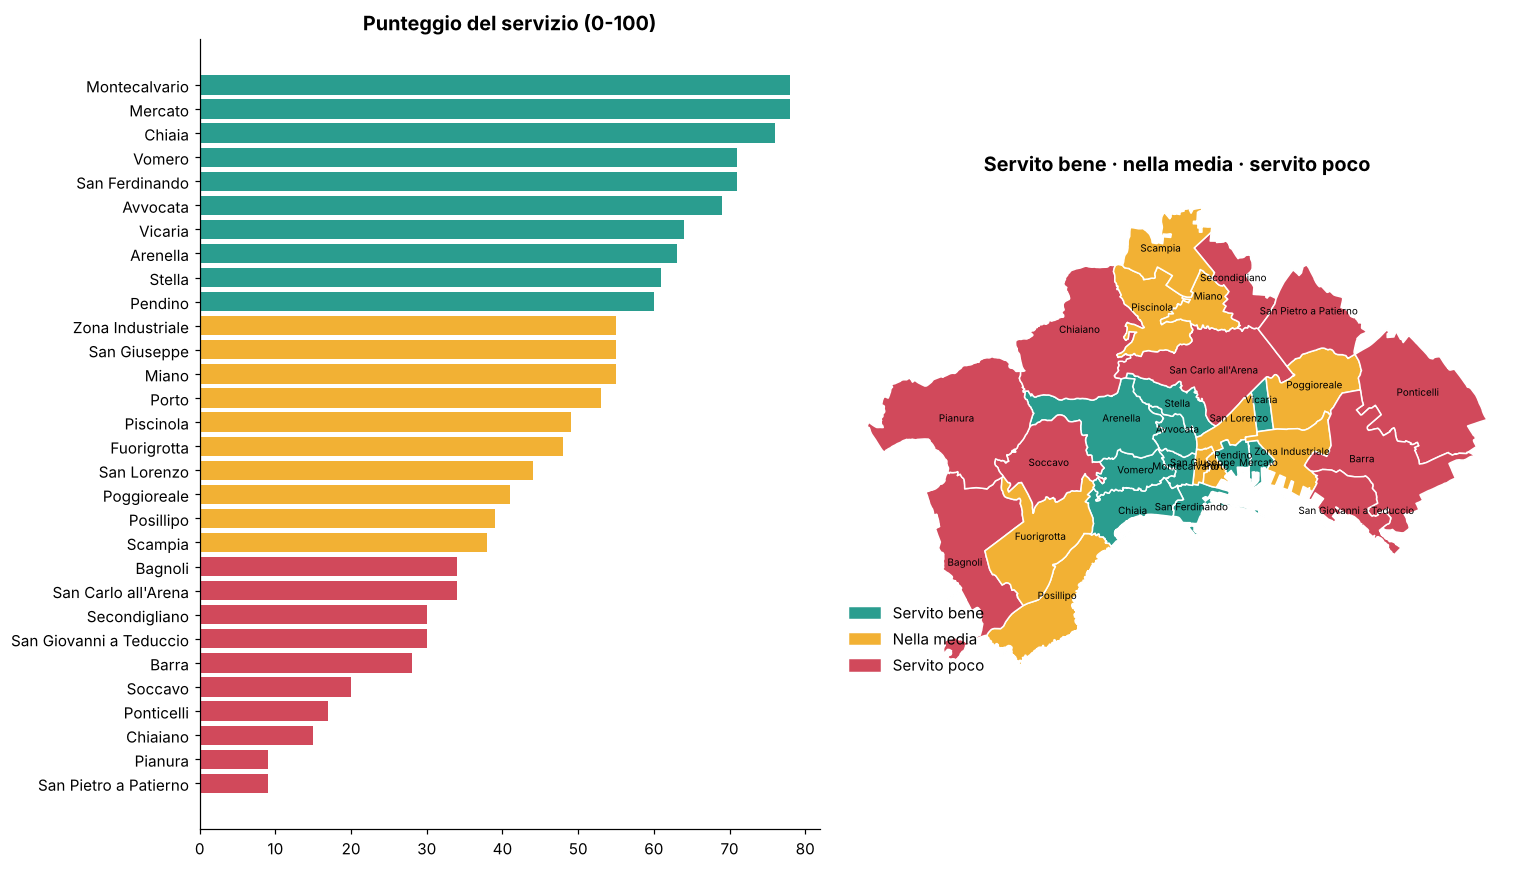

,posizione,quartiere,pct_entro_300m,pct_frequente_500m,pct_stazione_800m,punteggio_servizio
3,1,Montecalvario,100.0,100.0,100.0,78.0
9,1,Mercato,100.0,100.0,100.0,78.0
1,3,Chiaia,100.0,100.0,99.3,76.0
0,4,San Ferdinando,99.8,100.0,90.4,71.0
12,4,Vomero,100.0,100.0,90.3,71.0
4,6,Avvocata,97.6,99.9,99.9,69.0
7,7,Vicaria,100.0,100.0,57.0,64.0
13,8,Arenella,98.8,96.5,97.8,63.0
5,9,Stella,98.3,99.1,88.0,61.0
10,10,Pendino,88.8,100.0,100.0,60.0


In [9]:
o = q.sort_values("punteggio_servizio")
fig, ax = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].barh(o.quartiere, o.punteggio_servizio, color=[GIUDIZIO[g] for g in o.giudizio])
ax[0].set_title("Punteggio del servizio (0-100)")
confini.plot(ax=ax[1], color=[GIUDIZIO[g] for g in confini.giudizio], edgecolor="white", linewidth=1)
for _, r in q.iterrows():
    ax[1].text(r.longitudine, r.latitudine, r.quartiere, fontsize=6.5, ha="center", color="black")
ax[1].set_axis_off(); ax[1].set_title("Servito bene · nella media · servito poco")
ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GIUDIZIO.values()], labels=list(GIUDIZIO), loc="lower left", frameon=False)
salva("08_classifica")
q.sort_values("posizione")[["posizione", "quartiere", "pct_entro_300m", "pct_frequente_500m", "pct_stazione_800m", "punteggio_servizio"]].round(1)

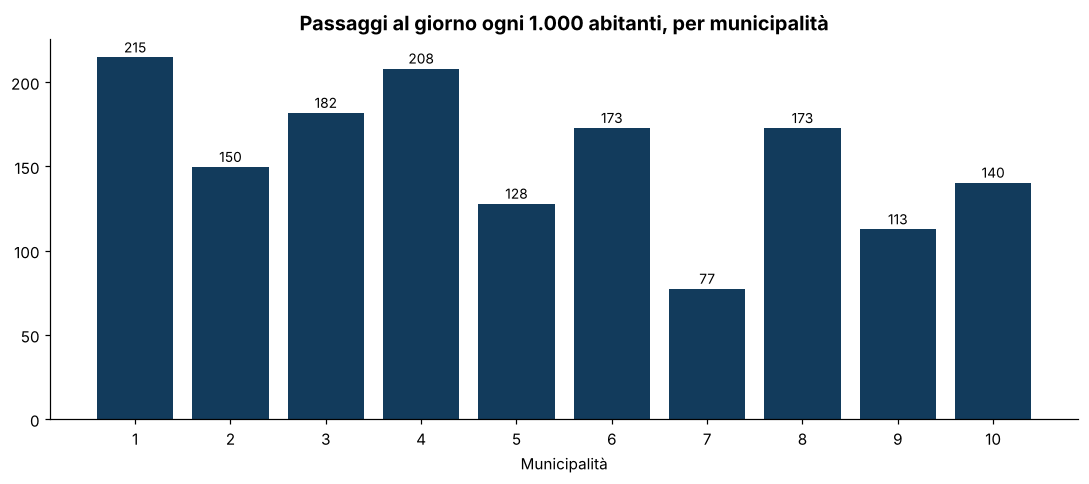

,municipalita,quartieri,abitanti,n_fermate,passaggi_1000_ab,pct_entro_300m
0,1,"San Ferdinando, Chiaia, Posillipo",88974.0,244,214.7,98.7
1,2,"San Giuseppe, Montecalvario, Avvocata, Mercato...",94460.0,111,149.7,95.0
2,3,"Stella, San Carlo all'Arena",95588.0,216,181.8,96.0
3,4,"Vicaria, San Lorenzo, Poggioreale, Zona Indust...",90651.0,184,208.1,88.7
4,5,"Vomero, Arenella",113976.0,193,127.9,99.3
5,6,"Ponticelli, Barra, San Giovanni a Teduccio",94473.0,255,172.9,92.2
6,7,"Miano, Secondigliano, San Pietro a Patierno",91278.0,138,77.4,94.3
7,8,"Chiaiano, Piscinola, Scampia",73015.0,201,172.8,89.9
8,9,"Soccavo, Pianura",88972.0,111,112.7,76.9
9,10,"Bagnoli, Fuorigrotta",89755.0,186,140.4,94.4


In [10]:
m = mun.sort_values("municipalita")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(m.municipalita.astype(str), m.passaggi_1000_ab, color=GOLFO)
for x, v in zip(m.municipalita.astype(str), m.passaggi_1000_ab):
    ax.text(x, v + 3, f"{v:.0f}", ha="center", fontsize=9)
ax.set_xlabel("Municipalità"); ax.set_title("Passaggi al giorno ogni 1.000 abitanti, per municipalità")
salva("09_municipalita")
m[["municipalita", "quartieri", "abitanti", "n_fermate", "passaggi_1000_ab", "pct_entro_300m"]].round(1)

💡 **Cosa vediamo**

📌 Servono meglio il **centro** e la **collina del Vomero**: Montecalvario, Mercato, Chiaia, San Ferdinando, Vomero.

📌 Servono peggio le **periferie**: Pianura, San Pietro a Patierno, Chiaiano, Ponticelli, Soccavo.

📌 La **Municipalità 7** (Miano, Secondigliano, San Pietro a Patierno) ha meno della metà dei passaggi per abitante della Municipalità 1.

## ✅ Conclusioni

1️⃣ 🚏 Le fermate sono tante e vicine: 9 napoletani su 10 ne hanno una a meno di 300 m (in media 135 m).

2️⃣ 🔁 Ma il servizio non è uguale: in periferia passano meno mezzi per abitante, soprattutto nella Municipalità 7.

3️⃣ 🚶 Si cammina di più a **Pianura**, Chiaiano e San Pietro a Patierno.

4️⃣ 🚇 Solo il 53% degli abitanti ha una metro o una funicolare a 10 minuti a piedi. Centro e Vomero sì, le periferie quasi mai (senza contare i treni EAV).

5️⃣ 🏆 Meglio serviti: centro e Vomero. Peggio serviti: le periferie a ovest, a nord e a est.

⚠️ Limiti: orari **programmati** dell'autunno 2023 (non i ritardi veri), distanze in linea d'aria, mancano i treni EAV e i bus regionali.